# DB-scan 


In [4]:
import profile
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys
import os
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score,davies_bouldin_score

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du
from src.utils import utils as ut
profile_df = pd.read_csv("../../data/profiles/patient_profile.csv")

profile_df.drop_duplicates(inplace=True)


profile_df

,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ptt,max_inr(pt),max_hemoglobin,max_wbc count,max_platelet count,max_white blood cells,abnormal_lab_event_ratio,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio
0,10000980,1,0,1,0,0,0,0,0,0,...,5.286957,2.0,-0.475000,0.0,0.251724,0.328571,0.410714,0.0,0.0,0.0
1,10002013,1,0,0,0,0,0,0,0,0,...,4.634783,0.5,0.025000,0.0,0.389655,0.714286,0.375000,0.0,0.0,0.0
2,10002155,1,0,0,0,0,0,0,0,0,...,5.661538,10.5,0.125000,0.0,0.341379,0.500000,0.384058,0.0,0.0,0.0
3,10004457,0,0,0,1,0,0,0,0,0,...,0.000000,0.0,-0.075000,0.0,0.396552,0.357143,0.300000,0.0,0.0,0.0
4,10007058,1,0,0,0,0,0,0,0,0,...,4.582609,1.5,-0.315789,0.0,0.220000,1.416667,0.375000,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4378,19998596,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4379,19998597,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4380,19998598,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4381,19998599,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0


In [5]:
profile_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4383 entries, 0 to 4382
Data columns (total 38 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   subject_id                        4383 non-null   int64  
 1   ACS_acute_ischemic                4383 non-null   int64  
 2   Chronic_ischemic                  4383 non-null   int64  
 3   Heart_failure                     4383 non-null   int64  
 4   Valvular_nonrheumatic             4383 non-null   int64  
 5   Myocarditis_or_cardiomyopathy     4383 non-null   int64  
 6   Pericardial_disease               4383 non-null   int64  
 7   Endocarditis                      4383 non-null   int64  
 8   Cardiac_arrest                    4383 non-null   int64  
 9   Arrhythmias_or_conduction         4383 non-null   int64  
 10  number_of_hadm                    4383 non-null   int64  
 11  gender                            4383 non-null   int64  
 12  age   

In [6]:
#correletion
profile_df['subject_id'] = profile_df['subject_id'].astype(str)
# Seleziona solo le colonne numeriche dal profilo paziente
numeric_cols = profile_df.select_dtypes(include='number').columns
profile_num= profile_df[numeric_cols]

#print the feautures with correlation higer than 0.8
corr_matrix = profile_num.corr().abs()
high_corr_var=np.where(corr_matrix>0.8)
high_corr_var=[(corr_matrix.columns[x],corr_matrix.columns[y]) for x,y in zip(*high_corr_var) if x!=y and x<y]
high_corr_var

[('lab_event_count', 'abnormal_lab_event_count'),
 ('unique_antibiotics_count', 'sensitive_microorganism_ratio')]

## some consideration
### sensitve_micro_ratio and unique-antibioti_count have a correlation>0.8 , for our analysis sensitve_micro_ratio is more signficant, I drop the other
### DA RICORDARSI PER IL JOIN: ABNOAMRL LAB EVENT COUNT VA DROPPATO, C'è IL RATIO

In [7]:
# Drop highly correlated features
profile_df= profile_df.drop(columns=['unique_antibiotics_count','gender'])

# Scale with min-max scaler
numeric_cols = profile_df.select_dtypes(include=['float64', 'int64']).columns.tolist()

#remoive columns with more than 0.8 of correlation



In [8]:
scaler = MinMaxScaler()
X = scaler.fit_transform(profile_df[numeric_cols].values)



In [9]:
#compute pairwise distance and distance matrix
dist = pdist(X, 'euclidean') #pair wise distance
print (dist)
dist = squareform(dist) #distance matrix given the vector dist
print()
print(dist)

[1.14808816 1.11045493 1.8823192  ... 1.42016416 1.42585338 1.44815386]

[[0.         1.14808816 1.11045493 ... 1.93692265 1.94647761 1.93814135]
 [1.14808816 0.         0.6244041  ... 1.58175949 1.58708202 1.59217491]
 [1.11045493 0.6244041  0.         ... 1.68238715 1.6873923  1.69218332]
 ...
 [1.93692265 1.58175949 1.68238715 ... 0.         1.42016416 1.42585338]
 [1.94647761 1.58708202 1.6873923  ... 1.42016416 0.         1.44815386]
 [1.93814135 1.59217491 1.69218332 ... 1.42585338 1.44815386 0.        ]]


## strategia 
### parto da min-sample 5, guardo il gomito e metto eps=0.3 : troppi cluster allora umento min_sample 
### con 8 min sapmle ancora troppi cluster
### provo 10 non va ancora 
### arrivata a 15 ho meno cluster ma anche con la scelta igliore di eps, troppo sbilanciati, aumenta ancora min_sample

In [10]:
k = 5
kth_distances = list()
for d in dist:
    index_kth_distance = np.argsort(d)[k]
    kth_distances.append(d[index_kth_distance])

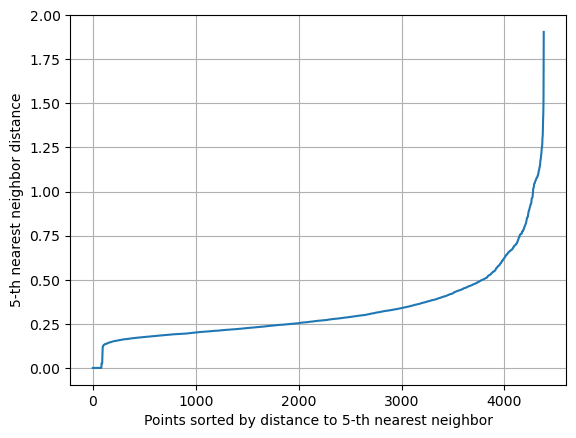

In [11]:
#plot the sorted kth distances witj grid 
kth_distances = np.array(kth_distances)
kth_distances = np.sort(kth_distances)
plt.plot(kth_distances)
plt.xlabel('Points sorted by distance to {}-th nearest neighbor'.format(k))
plt.ylabel('{}-th nearest neighbor distance'.format(k))
plt.grid()
plt.show()

In [12]:
# Funzione aggiornata per calcolare solo il Silhouette Score
epsList = [ 0.4, 0.5, 0.7, ]
best_ms, best_eps, best_silhouette = 0, 0, -1.0

for min_samples in range(5, 39):
    for eps in epsList:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        dbscan.fit(X)
        
        # Ottieni i cluster generati
        unique_labels, counts = np.unique(dbscan.labels_, return_counts=True)
        clusters = len(unique_labels)
        
        # Verifica il numero di cluster (escludendo noise se presente)
        if clusters > 1:
            silhouette = silhouette_score(X, dbscan.labels_)
            print(f'min_samples: {min_samples}, eps: {eps}, Silhouette Score: {silhouette:.4f}')
            
            # Aggiorna il miglior punteggio se necessario
            if silhouette > best_silhouette:
                best_silhouette = silhouette
                best_ms = min_samples
                best_eps = eps

print(f'\nBest min_samples: {best_ms}, Best eps: {best_eps}, Best Silhouette Score: {best_silhouette:.4f}')

min_samples: 5, eps: 0.4, Silhouette Score: 0.3433
min_samples: 5, eps: 0.5, Silhouette Score: 0.3834
min_samples: 5, eps: 0.7, Silhouette Score: 0.4016
min_samples: 6, eps: 0.4, Silhouette Score: 0.3430
min_samples: 6, eps: 0.5, Silhouette Score: 0.3816
min_samples: 6, eps: 0.7, Silhouette Score: 0.4059
min_samples: 7, eps: 0.4, Silhouette Score: 0.3383
min_samples: 7, eps: 0.5, Silhouette Score: 0.3787
min_samples: 7, eps: 0.7, Silhouette Score: 0.4063
min_samples: 8, eps: 0.4, Silhouette Score: 0.3550
min_samples: 8, eps: 0.5, Silhouette Score: 0.3824
min_samples: 8, eps: 0.7, Silhouette Score: 0.4113
min_samples: 9, eps: 0.4, Silhouette Score: 0.3558
min_samples: 9, eps: 0.5, Silhouette Score: 0.3832
min_samples: 9, eps: 0.7, Silhouette Score: 0.4166
min_samples: 10, eps: 0.4, Silhouette Score: 0.4208
min_samples: 10, eps: 0.5, Silhouette Score: 0.3833
min_samples: 10, eps: 0.7, Silhouette Score: 0.4282
min_samples: 11, eps: 0.4, Silhouette Score: 0.4249
min_samples: 11, eps: 0.5, 

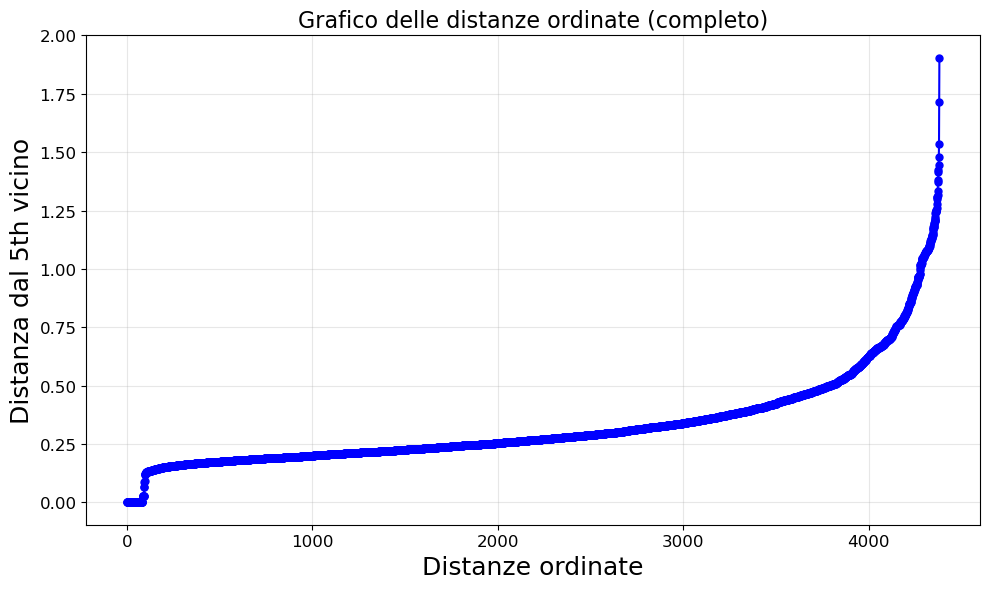

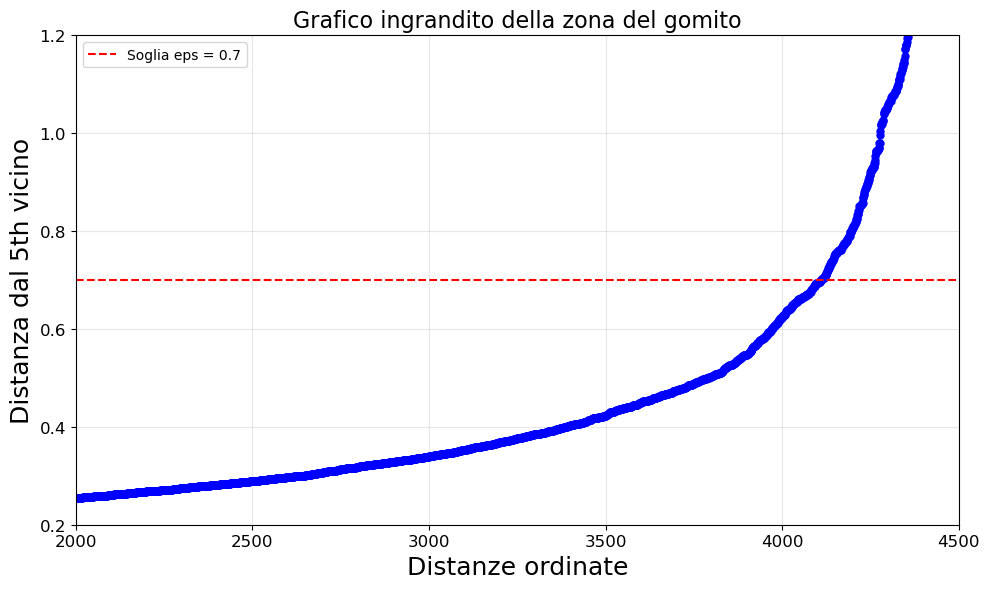

In [13]:
# Plot completo delle distanze ordinate
plt.figure(figsize=(10, 6))
plt.plot(range(0, len(kth_distances)), sorted(kth_distances), color='blue', linestyle='-', marker='o', markersize=5)
plt.ylabel('Distanza dal %sth vicino' % k, fontsize=18)
plt.xlabel('Distanze ordinate', fontsize=18)
plt.tick_params(axis='both', which='major', labelsize=12)
plt.title("Grafico delle distanze ordinate (completo)", fontsize=16)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot ingrandito della zona del gomito
plt.figure(figsize=(10, 6))
plt.plot(range(0, len(kth_distances)), sorted(kth_distances), color='blue', linestyle='-', marker='o', markersize=5)
plt.xlim(2000, 4500)  # Limita l'asse X per concentrarti sui primi punti
plt.ylim(0.2, 1.2)  # Limita l'asse Y per concentrarti sulla zona del gomito
plt.ylabel('Distanza dal %sth vicino' % k, fontsize=18)
plt.xlabel('Distanze ordinate', fontsize=18)
plt.tick_params(axis='both', which='major', labelsize=12)
plt.axhline(y=best_eps, color='red', linestyle='--', label=f'Soglia eps = {best_eps}')
plt.title("Grafico ingrandito della zona del gomito", fontsize=16)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
# Raffina la ricerca di eps attorno al valore migliore trovato
for eps_ in np.linspace(0.5, 0.8, 4):    
    dbscan = DBSCAN(eps=eps_, min_samples=best_ms)
    dbscan.fit(X)
    np.unique(dbscan.labels_, return_counts=True)
    clusters = len(np.unique(dbscan.labels_))
    
    if clusters > 1:
        silhouette = silhouette_score(X, dbscan.labels_)
        davies_bouldin = davies_bouldin_score(X, dbscan.labels_)
        print('minsample = %s, eps= %s => K= %s, Silhouette %s, Davies-Bouldin %s' % 
              (best_ms, eps_, clusters, silhouette, davies_bouldin))
        
        # Aggiorna best_eps se troviamo un silhouette migliore
        if silhouette > best_silhouette:
            best_silhouette = silhouette
            best_eps = eps_
    else:
        print('minsample = %s, eps= %s => K= %s, Silhouette N/A (solo 1 cluster)' % (best_ms, eps_, clusters))

print(f'\n=== Parametri finali migliori ===')
print(f'Best min_samples: {best_ms}')
print(f'Best eps: {best_eps}')
print(f'Best Silhouette Score: {best_silhouette:.4f}')

minsample = 30, eps= 0.5 => K= 8, Silhouette 0.45613647152987924, Davies-Bouldin 1.5267870274733564
minsample = 30, eps= 0.6 => K= 8, Silhouette 0.4742476112033663, Davies-Bouldin 1.503970512361875
minsample = 30, eps= 0.7000000000000001 => K= 8, Silhouette 0.48411329588498825, Davies-Bouldin 1.5252878366763918
minsample = 30, eps= 0.8 => K= 12, Silhouette 0.43324361669301403, Davies-Bouldin 1.4951482729492849

=== Parametri finali migliori ===
Best min_samples: 30
Best eps: 0.7
Best Silhouette Score: 0.4841


In [15]:

dbscan = DBSCAN(eps= best_eps,min_samples= best_ms)
dbscan.fit(X)

,eps,0.7
,min_samples,30
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


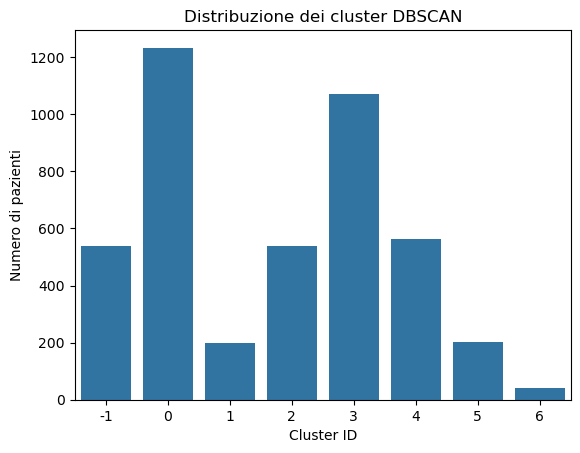

In [16]:
# Aggiungi i cluster assegnati al DataFrame
profile_df['cluster'] = dbscan.labels_

# Ora puoi creare il grafico
sns.countplot(x='cluster', data=profile_df)
plt.title("Distribuzione dei cluster DBSCAN")
plt.xlabel("Cluster ID")
plt.ylabel("Numero di pazienti")
plt.show()

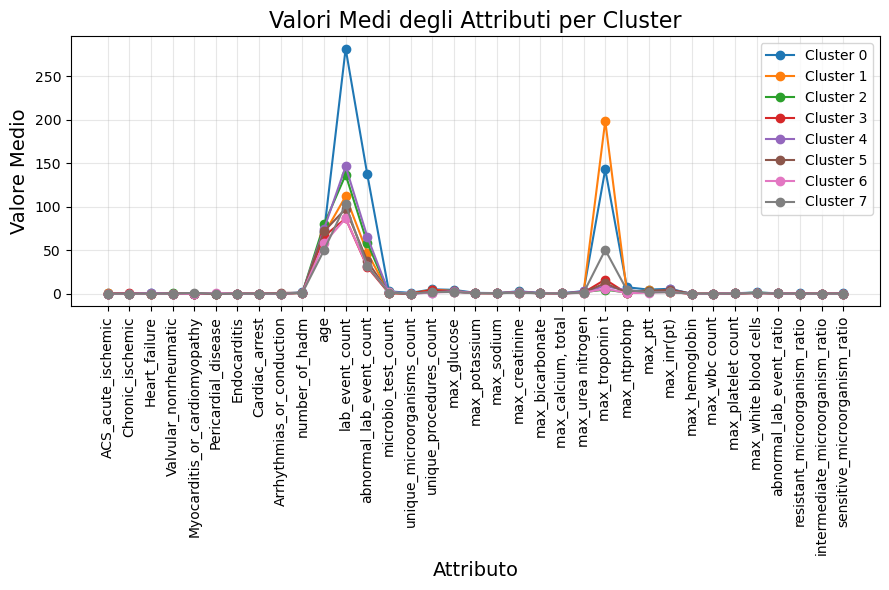

In [17]:
# Aggiungi 1 ai cluster per evitare valori negativi (noise diventa 0)
profile_df["cluster"] = dbscan.labels_ + 1

# Calcola le medie per cluster, escludendo subject_id
numeric_cols_for_plot = [col for col in profile_df.columns if col not in ['subject_id', 'cluster']]
means = profile_df.groupby('cluster')[numeric_cols_for_plot].mean()

# Crea un grafico a linee per ciascun cluster
plt.figure(figsize=(9, 6))
for cluster in means.index:
    plt.plot(means.columns, means.loc[cluster], marker='o', label=f'Cluster {cluster}')

plt.xlabel('Attributo', fontsize=14)
plt.ylabel('Valore Medio', fontsize=14)
plt.title('Valori Medi degli Attributi per Cluster', fontsize=16)
plt.legend()
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

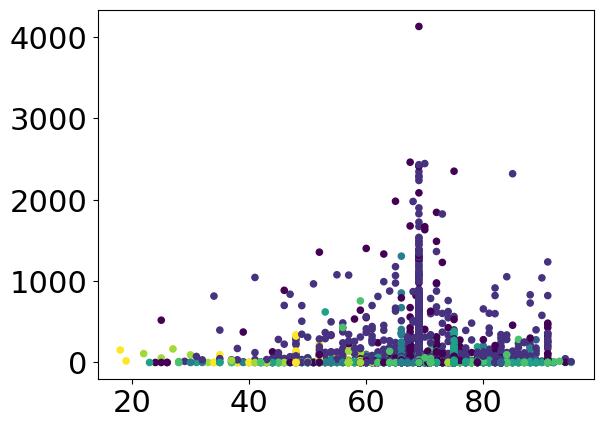

In [18]:


# Ora puoi creare il grafico
plt.scatter(profile_df['age'], profile_df['max_troponin t'], c=dbscan.labels_, s=20)
plt.tick_params(axis='both', which='major', labelsize=22)
plt.show()

# Analisi Approfondita dei Cluster

Analizziamo i cluster creati con DBSCAN per comprendere le caratteristiche dei diversi gruppi di pazienti.

In [19]:
# 1. Statistiche generali sui cluster
print("=" * 60)
print("STATISTICHE GENERALI SUI CLUSTER")
print("=" * 60)

# Conta i pazienti per cluster
cluster_counts = profile_df['cluster'].value_counts().sort_index()
print(f"\nNumero totale di pazienti: {len(profile_df)}")
print(f"Numero di cluster (incluso noise): {len(cluster_counts)}")
print("\nDistribuzione pazienti per cluster:")
for cluster_id, count in cluster_counts.items():
    percentage = (count / len(profile_df)) * 100
    cluster_name = "Noise" if cluster_id == 0 else f"Cluster {cluster_id}"
    print(f"  {cluster_name}: {count} pazienti ({percentage:.2f}%)")

# Calcola metriche di qualità
if len(cluster_counts) > 1:
    # Escludiamo il noise (cluster 0) per calcolare le metriche
    non_noise_mask = profile_df['cluster'] != 0
    if non_noise_mask.sum() > 0:
        silhouette = silhouette_score(X[non_noise_mask], profile_df.loc[non_noise_mask, 'cluster'])
        davies_bouldin = davies_bouldin_score(X[non_noise_mask], profile_df.loc[non_noise_mask, 'cluster'])
        print(f"\nMetriche di qualità (escludendo noise):")
        print(f"  Silhouette Score: {silhouette:.4f} (range: [-1, 1], migliore se vicino a 1)")
        print(f"  Davies-Bouldin Index: {davies_bouldin:.4f} (migliore se basso)")

STATISTICHE GENERALI SUI CLUSTER

Numero totale di pazienti: 4383
Numero di cluster (incluso noise): 8

Distribuzione pazienti per cluster:
  Noise: 537 pazienti (12.25%)
  Cluster 1: 1233 pazienti (28.13%)
  Cluster 2: 198 pazienti (4.52%)
  Cluster 3: 537 pazienti (12.25%)
  Cluster 4: 1072 pazienti (24.46%)
  Cluster 5: 562 pazienti (12.82%)
  Cluster 6: 203 pazienti (4.63%)
  Cluster 7: 41 pazienti (0.94%)

Metriche di qualità (escludendo noise):
  Silhouette Score: 0.5869 (range: [-1, 1], migliore se vicino a 1)
  Davies-Bouldin Index: 0.6359 (migliore se basso)


In [20]:
# 2. Statistiche descrittive per ogni cluster (tabella riassuntiva)
# Escludi subject_id e cluster dalle colonne numeriche
numeric_cols_analysis = [col for col in profile_df.columns if col not in ['subject_id', 'cluster']]

# Crea una tabella riassuntiva con le medie per cluster
cluster_summary = profile_df.groupby('cluster')[numeric_cols_analysis].mean()
cluster_summary['n_pazienti'] = profile_df.groupby('cluster').size().astype(int)

# Identifica le colonne da arrotondare come interi (conteggi e età)
int_cols = [col for col in cluster_summary.columns if 'count' in col.lower() or col == 'age']
for col in int_cols:
    cluster_summary[col] = cluster_summary[col].round(0).astype(int)

# Arrotonda le altre colonne a 3 decimali
other_cols = [col for col in cluster_summary.columns if col not in int_cols and col != 'n_pazienti']
cluster_summary[other_cols] = cluster_summary[other_cols].round(3)

# Riordina le colonne per mettere il conteggio all'inizio
cols = ['n_pazienti'] + [col for col in cluster_summary.columns if col != 'n_pazienti']
cluster_summary = cluster_summary[cols]

print("\nSTATISTICHE DESCRITTIVE PER CLUSTER (Medie)")
print("=" * 60)
display(cluster_summary)


STATISTICHE DESCRITTIVE PER CLUSTER (Medie)


,n_pazienti,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ptt,max_inr(pt),max_hemoglobin,max_wbc count,max_platelet count,max_white blood cells,abnormal_lab_event_ratio,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio
cluster,,,,,,,,,,,,,,,,,,,,,
0,537,0.365,0.173,0.415,0.132,0.015,0.05,0.071,0.004,0.175,...,4.699,5.644,-0.222,0,1,1.398,0.445,0.332,0.127,0.529
1,1233,1.000,0.000,0.000,0.000,0.000,0.00,0.000,0.000,0.000,...,3.797,2.199,-0.108,0,0,1.004,0.362,0.002,0.000,0.015
2,198,0.000,0.000,0.000,1.000,0.000,0.00,0.000,0.000,0.000,...,3.181,3.250,-0.237,0,0,1.214,0.382,0.000,0.000,0.000
3,537,0.000,1.000,0.000,0.000,0.000,0.00,0.000,0.000,0.000,...,2.407,1.930,-0.092,0,0,0.749,0.291,0.001,0.000,0.017
4,1072,0.000,0.000,1.000,0.000,0.000,0.00,0.000,0.000,0.000,...,2.164,4.960,-0.286,0,0,0.783,0.397,0.003,0.000,0.017
5,562,0.000,0.000,0.000,0.000,0.000,0.00,0.000,0.000,1.000,...,3.034,4.749,-0.083,0,0,0.844,0.325,0.000,0.000,0.002
6,203,0.000,0.000,0.000,0.000,0.000,1.00,0.000,0.000,0.000,...,1.275,1.991,-0.200,0,1,0.917,0.316,0.002,0.002,0.012
7,41,0.000,0.000,0.000,0.000,1.000,0.00,0.000,0.000,0.000,...,1.538,1.707,0.048,0,0,0.828,0.278,0.000,0.000,0.000


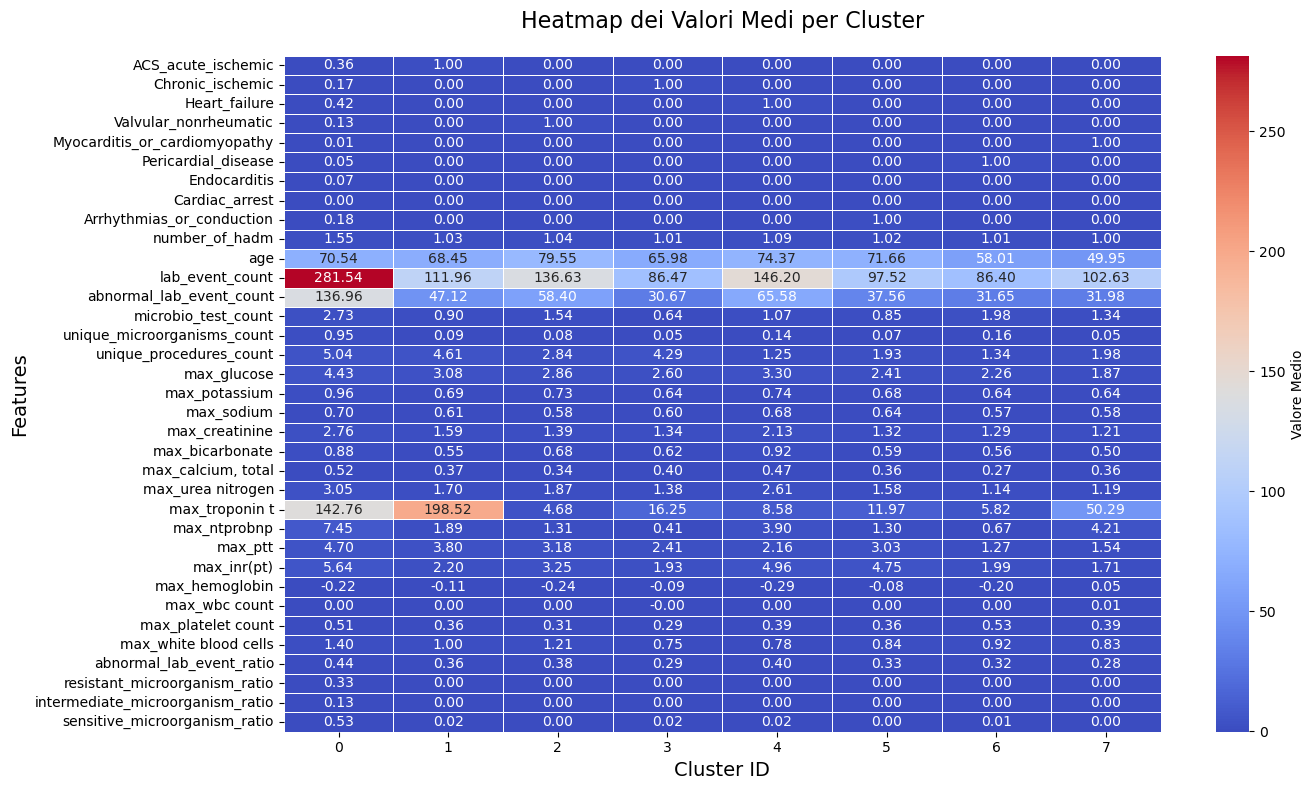

In [21]:
# 3. Confronto tra cluster - Heatmap delle medie
plt.figure(figsize=(14, 8))

# Calcola le medie per ogni cluster
cluster_means = profile_df.groupby('cluster')[numeric_cols_analysis].mean()

# Crea la heatmap
sns.heatmap(cluster_means.T, annot=True, fmt='.2f', cmap='coolwarm', 
            cbar_kws={'label': 'Valore Medio'}, linewidths=0.5)
plt.title('Heatmap dei Valori Medi per Cluster', fontsize=16, pad=20)
plt.xlabel('Cluster ID', fontsize=14)
plt.ylabel('Features', fontsize=14)
plt.tight_layout()
plt.show()

### Interpretazione della Heatmap

La heatmap mostra i **valori medi** di ogni feature per ciascun cluster:

- **Colori caldi (rosso/arancione)**: valori più alti della feature
- **Colori freddi (blu)**: valori più bassi della feature
- **Righe**: rappresentano le diverse features (variabili)
- **Colonne**: rappresentano i diversi cluster

**Come leggere la heatmap:**
1. Confronta **orizzontalmente** (lungo una riga) per vedere come una specifica feature varia tra i cluster
2. Confronta **verticalmente** (lungo una colonna) per vedere il profilo completo di un cluster
3. I cluster con **pattern di colori simili** hanno caratteristiche simili
4. Le **differenze marcate di colore** indicano caratteristiche distintive di un cluster

### Caratterizzazione dei Cluster - Spiegazione

Questa analisi identifica le **caratteristiche distintive** di ogni cluster confrontandolo con la media globale:

**Cosa calcola:**
1. **Media globale**: calcola il valore medio di ogni feature su tutti i pazienti
2. **Media per cluster**: calcola il valore medio di ogni feature per i pazienti di un singolo cluster
3. **Deviazione percentuale**: calcola quanto il cluster si discosta dalla media globale usando la formula:
   ```
   deviazione % = ((valore_cluster - valore_globale) / valore_globale) * 100
   ```

**Come interpretare i risultati:**
- **Deviazione positiva alta** (es. +50%): il cluster ha valori molto più alti della media per quella feature
- **Deviazione negativa alta** (es. -50%): il cluster ha valori molto più bassi della media
- Le feature con **maggiore deviazione** sono quelle che caratterizzano meglio il cluster

**Esempio pratico:**
Se un cluster ha "age: 75 vs 65 (media) - più alto del 15.4%", significa che i pazienti in quel cluster sono in media 15% più anziani rispetto alla popolazione totale.

In [22]:
# Calcola le medie globali per il confronto
global_means = profile_df[numeric_cols_analysis].mean()

# Identifica le variabili diagnostiche
diagnosis_cols = [
    'ACS_acute_ischemic', 'Chronic_ischemic', 'Heart_failure',
    'Valvular_nonrheumatic', 'Myocarditis_or_cardiomyopathy',
    'Pericardial_disease', 'Endocarditis', 'Cardiac_arrest',
    'Arrhythmias_or_conduction'
]

# Variabili cliniche (tutto il resto)
clinical_cols = [col for col in numeric_cols_analysis if col not in diagnosis_cols]

print("\n" + "="*60)
print("CARATTERIZZAZIONE DEI CLUSTER")
print("="*60)

for cluster_id in sorted(profile_df['cluster'].unique()):
    cluster_name = "NOISE" if cluster_id == 0 else f"CLUSTER {cluster_id}"
    cluster_data = profile_df[profile_df['cluster'] == cluster_id]
    
    print(f"\n{cluster_name} - {len(cluster_data)} pazienti")
    print("-"*60)
    
    cluster_means = cluster_data[numeric_cols_analysis].mean()
    
    # ========================================
    # 1. DIAGNOSI PREVALENTI
    # ========================================
    print("\n📋 DIAGNOSI PREVALENTI:")
    diagnosi_trovate = False
    for diag in diagnosis_cols:
        if diag in cluster_means.index:
            cluster_val = cluster_means[diag]
            global_val = global_means[diag]
            if cluster_val > 0.5:  # Prevalenza > 50%
                print(f"  • {diag:35s}: {cluster_val:5.1%}")
                diagnosi_trovate = True
    
    if not diagnosi_trovate:
        print("  Nessuna diagnosi prevalente (>50%)")
    
    # ========================================
    # 2. CARATTERISTICHE CLINICHE DISTINTIVE
    # ========================================
    print("\n🔬 CARATTERISTICHE CLINICHE DISTINTIVE:")
    
    # Calcola deviazioni solo per variabili cliniche
    clinical_deviations = {}
    for feature in clinical_cols:
        cluster_val = cluster_means[feature]
        global_val = global_means[feature]
        if abs(global_val) > 0.01:  # Evita divisione per ~0
            deviation = abs((cluster_val - global_val) / global_val * 100)
            clinical_deviations[feature] = deviation
    
    # Top 5 caratteristiche cliniche
    sorted_clinical = sorted(clinical_deviations.items(), 
                            key=lambda x: x[1], 
                            reverse=True)[:5]
    
    for i, (feature, deviation) in enumerate(sorted_clinical, 1):
        cluster_val = cluster_means[feature]
        global_val = global_means[feature]
        direction = "↑" if cluster_val > global_val else "↓"
        print(f"  {i}. {feature:30s}: {cluster_val:7.2f} vs {global_val:7.2f} {direction}")
    
    # ========================================
    # 3. PROFILO DEMOGRAFICO
    # ========================================
    if 'age' in clinical_cols:
        age_cluster = cluster_means['age']
        age_global = global_means['age']
        print(f"\n👤 ETÀ MEDIA: {age_cluster:.1f} anni (media globale: {age_global:.1f})")
    
    # ========================================
    # 4. COMPLESSITÀ CLINICA
    # ========================================
    complexity_indicators = ['lab_event_count', 'abnormal_lab_event_count', 
                            'number_of_hadm', 'microbio_test_count']
    print(f"\n📊 COMPLESSITÀ CLINICA:")
    for indicator in complexity_indicators:
        if indicator in clinical_cols:
            cluster_val = cluster_means[indicator]
            global_val = global_means[indicator]
            diff = cluster_val - global_val
            symbol = "+" if diff > 0 else ""
            print(f"  • {indicator:30s}: {cluster_val:6.1f} ({symbol}{diff:+.1f} vs media)")


CARATTERIZZAZIONE DEI CLUSTER

NOISE - 537 pazienti
------------------------------------------------------------

📋 DIAGNOSI PREVALENTI:
  Nessuna diagnosi prevalente (>50%)

🔬 CARATTERISTICHE CLINICHE DISTINTIVE:
  1. intermediate_microorganism_ratio:    0.13 vs    0.02 ↑
  2. resistant_microorganism_ratio :    0.33 vs    0.04 ↑
  3. sensitive_microorganism_ratio :    0.53 vs    0.08 ↑
  4. unique_microorganisms_count   :    0.95 vs    0.20 ↑
  5. max_ntprobnp                  :    7.45 vs    2.74 ↑

👤 ETÀ MEDIA: 70.5 anni (media globale: 70.1)

📊 COMPLESSITÀ CLINICA:
  • lab_event_count               :  281.5 (++145.6 vs media)
  • abnormal_lab_event_count      :  137.0 (++77.9 vs media)
  • number_of_hadm                :    1.6 (++0.4 vs media)
  • microbio_test_count           :    2.7 (++1.5 vs media)

CLUSTER 1 - 1233 pazienti
------------------------------------------------------------

📋 DIAGNOSI PREVALENTI:
  • ACS_acute_ischemic                 : 100.0%

🔬 CARATTERISTICHE C

### cluester 0: pazienti complessi che non rientrano nei pattern tipici, probabilmente con comorbidità infettive sovrapposte.  aratteristica principale :Infezioni e complicanze settiche
### cluster 1: raccoglie tutti i pazienti ricoverati d'urgenza per un attacco di cuore grave, ed è il gruppo più grande dello studio. Tutti i pazienti del cluster hanno la stessa diagnosi: infarto. Non c'è confusione con altre malattie cardiache.
### cluster 2: 100% valvulopatie non reumatiche
### cluster 3: 100% ischemia cronica.Sono pazienti con coronarie ristrette da tempo, ma stabili - non stanno avendo un infarto adesso. Non c'è emergenza: niente infarto in corso, niente scompensoI globuli bianchi sono normali → nessuna infiammazione acuta.La troponina è bassa (16.25 dalla heatmap) → nessun danno attivo al cuore
### cluster 4: 100% insufficienza cardiaca . Numerosi eventi di laboratorio (heatmap)
### cluster 5:
### cluster 6:
### cluster 7:

### NOISE